# Milestone 3 — direct safe-haven findings

Companion to notebook 03. Same 55-feature pipeline as Milestone 2.

1. Does Gold defend more as stress intensifies? (deciles)
2. Is Bitcoin “digital gold”? (beta, tails, drawdowns)
3. What drives Model E? (themed SHAP, logistic vs XGBoost, calm vs stress)
4. Why the MLP failed (train/test gap, KS shift, regularized rerun)


## Setup — same M2 feature pipeline


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, brier_score_loss,
    log_loss, accuracy_score, f1_score,
)
from xgboost import XGBClassifier
import xgboost as xgb

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
np.random.seed(42)

HERE = Path.cwd()
REPO_ROOT = HERE if (HERE / "src" / "macro_stress").exists() else HERE.parent
DATA_PATH = REPO_ROOT / "data" / "Global_Market_Stress_and_Liquidity_Regimes.csv"
FIG_DIR = REPO_ROOT / "figures" / "notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.is_file():
    raise SystemExit("Put the Kaggle CSV at data/Global_Market_Stress_and_Liquidity_Regimes.csv")

TEST_SIZE = 0.2
LAGS = [1, 3, 5]
N_BOOT = 2000

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df["gold_ret"] = np.log(df["Gold"]).diff()
df["spy_ret"] = np.log(df["Equities_US"]).diff()
df["btc_ret"] = np.log(df["Crypto_Bitcoin"]).diff()
df["Gold_Rolling_Vol_30d"] = df["gold_ret"].rolling(30).std() * np.sqrt(252)

def regime_from_quantile(s, q=0.66):
    return (s >= s.quantile(q)).astype(int)

df["stress_hys"] = regime_from_quantile(df["High_Yield_Spread"])
df["stress_fsi"] = regime_from_quantile(df["Financial_Stress_Index"])
df["stress_vix"] = regime_from_quantile(df["Volatility_Index"])
df["stress_any"] = ((df["stress_hys"] + df["stress_fsi"] + df["stress_vix"]) >= 1).astype(int)
df["stress_all"] = ((df["stress_hys"] + df["stress_fsi"] + df["stress_vix"]) == 3).astype(int)

MACRO_LEVELS = [
    "Volatility_Index", "Yield_Curve_Spread", "High_Yield_Spread",
    "Financial_Stress_Index", "SPY_Drawdown", "Stock_Bond_Corr_90d",
    "SPY_RSI_14", "GLD_RSI_14",
]
VOL_LEVELS = ["SPY_Rolling_Vol_30d", "BTC_Rolling_Vol_30d", "Gold_Rolling_Vol_30d"]
RET_COLS = ["gold_ret", "spy_ret", "btc_ret"]

feat = pd.DataFrame(index=df.index)
feat["Date"] = df["Date"]
for c in MACRO_LEVELS + VOL_LEVELS:
    feat[c] = df[c]
    for L in LAGS:
        feat[f"{c}_lag{L}"] = df[c].shift(L)
for c in RET_COLS:
    for L in LAGS:
        feat[f"{c}_lag{L}"] = df[c].shift(L)
feat["stress_hys_t"] = df["stress_hys"]
feat["stress_any_t"] = df["stress_any"]
for col in RET_COLS:
    feat[col] = df[col]
feat["stress_hys"] = df["stress_hys"]
feat["stress_any"] = df["stress_any"]

EXCLUDE = ["Date"] + RET_COLS + ["stress_hys", "stress_any"]
FEATURE_COLS = [c for c in feat.columns if c not in EXCLUDE]
assert len(FEATURE_COLS) == 55, len(FEATURE_COLS)

target_E = (df["gold_ret"].shift(-1) > df["spy_ret"].shift(-1)).astype(float)
target_E[df["gold_ret"].shift(-1).isna() | df["spy_ret"].shift(-1).isna()] = np.nan

def chrono_split(data, feature_cols, target, test_size=TEST_SIZE):
    aligned = data.loc[target.dropna().index].copy()
    aligned = aligned.dropna(subset=feature_cols)
    y = target.loc[aligned.index]
    n_test = max(1, int(len(aligned) * test_size))
    split_idx = len(aligned) - n_test
    return (
        aligned.iloc[:split_idx][feature_cols].values,
        aligned.iloc[split_idx:][feature_cols].values,
        y.iloc[:split_idx].values,
        y.iloc[split_idx:].values,
        aligned.iloc[:split_idx]["Date"].values,
        aligned.iloc[split_idx:]["Date"].values,
    )

X_tr_E, X_te_E, y_tr_E, y_te_E, d_tr_E, d_te_E = chrono_split(feat, FEATURE_COLS, target_E)
y_tr_E = y_tr_E.astype(int); y_te_E = y_te_E.astype(int)
print(f"Rows total: {len(df)}; predictors: {len(FEATURE_COLS)}")
print(f"Model E train: {len(y_tr_E)} ({pd.Timestamp(d_tr_E[0]).date()} -> {pd.Timestamp(d_tr_E[-1]).date()})")
print(f"Model E test : {len(y_te_E)} ({pd.Timestamp(d_te_E[0]).date()} -> {pd.Timestamp(d_te_E[-1]).date()})")


Rows total: 4150; predictors: 55
Model E train: 3292 (2014-11-21 -> 2023-11-25)
Model E test : 822 (2023-11-26 -> 2026-02-24)


## Does Gold defend more as stress intensifies? — decile view

Bin VIX, high-yield spread, and the financial stress index into deciles. Plot mean (Gold−SPY) daily log-return spread and mean Gold return per decile, with bootstrap 95% CIs.


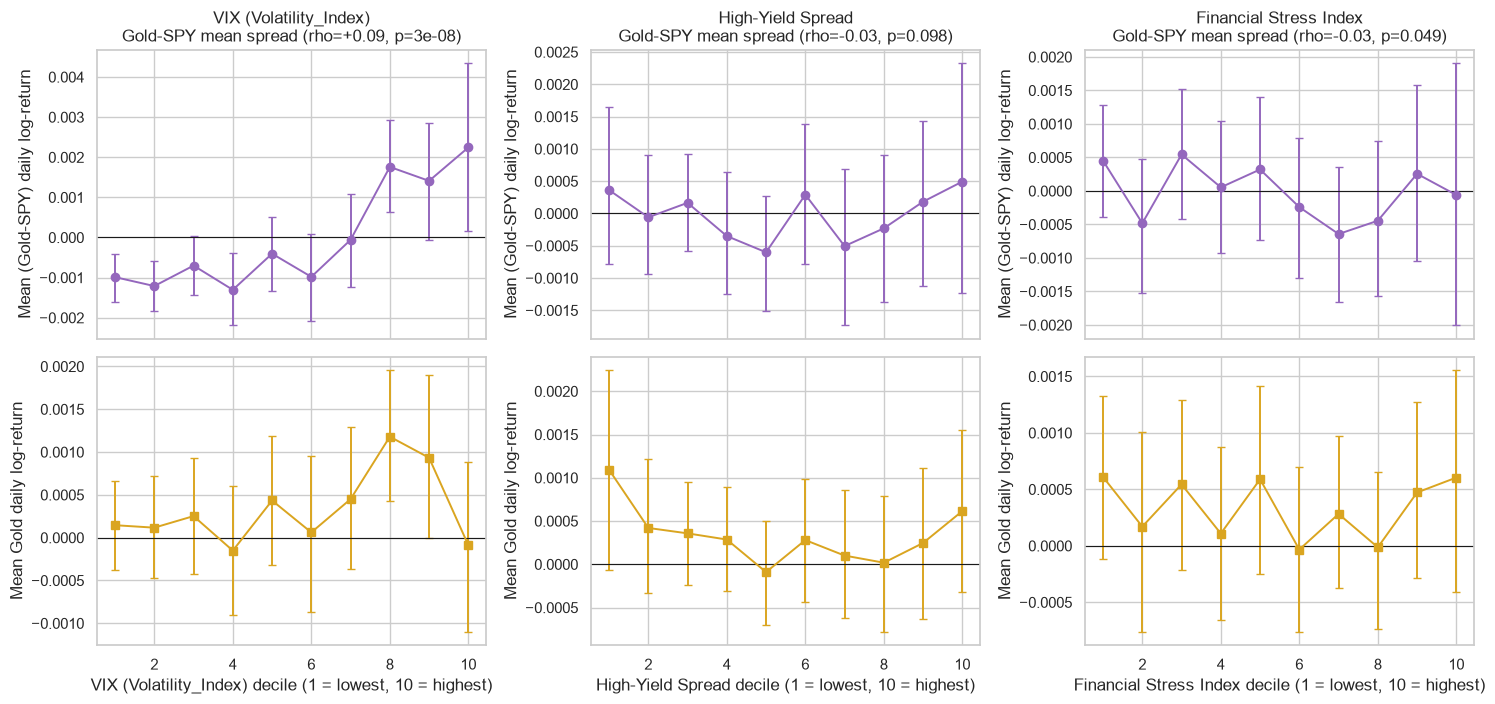

,driver,spearman_decile_vs_GoldSPY_spread,p_value
0,VIX (Volatility_Index),0.0859,0.0000
1,High-Yield Spread,-0.0257,0.0979
2,Financial Stress Index,-0.0305,0.0493


In [2]:
DRIVERS = {
    "VIX (Volatility_Index)": "Volatility_Index",
    "High-Yield Spread": "High_Yield_Spread",
    "Financial Stress Index": "Financial_Stress_Index",
}
spread = df["gold_ret"] - df["spy_ret"]
gold = df["gold_ret"]

def bootstrap_mean_ci(x, n_boot=N_BOOT, alpha=0.05, seed=0):
    x = np.asarray(pd.Series(x).dropna())
    if len(x) < 5:
        return float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    means = np.empty(n_boot)
    for i in range(n_boot):
        means[i] = rng.choice(x, size=len(x), replace=True).mean()
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return float(x.mean()), float(lo), float(hi)

fig, axes = plt.subplots(2, len(DRIVERS), figsize=(5.0 * len(DRIVERS), 7.2), sharex="col")
spearman_rows = []
for j, (label, col) in enumerate(DRIVERS.items()):
    deciles = pd.qcut(df[col], q=10, labels=False, duplicates="drop") + 1
    spread_means, spread_los, spread_his = [], [], []
    gold_means, gold_los, gold_his = [], [], []
    deciles_present = sorted(int(d) for d in deciles.dropna().unique())
    for d in deciles_present:
        mask = (deciles == d).values
        m, lo, hi = bootstrap_mean_ci(spread[mask], seed=10 * j + d)
        spread_means.append(m); spread_los.append(lo); spread_his.append(hi)
        gm, glo, ghi = bootstrap_mean_ci(gold[mask], seed=10 * j + d + 100)
        gold_means.append(gm); gold_los.append(glo); gold_his.append(ghi)
    valid = deciles.dropna()
    sp_rho, sp_p = stats.spearmanr(valid.values, spread.loc[valid.index].values, nan_policy="omit")
    spearman_rows.append({"driver": label, "spearman_decile_vs_GoldSPY_spread": float(sp_rho), "p_value": float(sp_p)})
    ax = axes[0, j]
    ax.errorbar(
        deciles_present, spread_means,
        yerr=[np.array(spread_means) - np.array(spread_los), np.array(spread_his) - np.array(spread_means)],
        marker="o", color="tab:purple", lw=1.4, capsize=3,
    )
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{label}\nGold-SPY mean spread (rho={sp_rho:+.2f}, p={sp_p:.2g})")
    ax.set_ylabel("Mean (Gold-SPY) daily log-return")
    ax = axes[1, j]
    ax.errorbar(
        deciles_present, gold_means,
        yerr=[np.array(gold_means) - np.array(gold_los), np.array(gold_his) - np.array(gold_means)],
        marker="s", color="goldenrod", lw=1.4, capsize=3,
    )
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(f"{label} decile (1 = lowest, 10 = highest)")
    ax.set_ylabel("Mean Gold daily log-return")
plt.tight_layout()
plt.savefig(FIG_DIR / "m4_deciles.png", dpi=140, bbox_inches="tight")
plt.show()
display(pd.DataFrame(spearman_rows).round(4))


## Is Bitcoin “digital gold”? Beta, tails, drawdowns


In [3]:
def beta_to_spy(asset_ret, spy_ret, mask, n_boot=1000, seed=0):
    a = pd.Series(asset_ret).loc[mask].dropna()
    s = pd.Series(spy_ret).loc[a.index].dropna()
    a, s = a.loc[s.index], s
    if len(a) < 30:
        return float("nan"), float("nan"), float("nan")
    slope = stats.linregress(s.values, a.values).slope
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    arr_a, arr_s, n = a.values, s.values, len(a)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[i] = stats.linregress(arr_s[idx], arr_a[idx]).slope
    lo, hi = np.quantile(boot, [0.025, 0.975])
    return float(slope), float(lo), float(hi)

calm_mask = (df["stress_any"] == 0) & df[RET_COLS].notna().all(axis=1)
stress_mask = (df["stress_any"] == 1) & df[RET_COLS].notna().all(axis=1)
beta_rows = []
for asset_label, ret_col in [("Gold", "gold_ret"), ("BTC", "btc_ret")]:
    b_calm, lo_c, hi_c = beta_to_spy(df[ret_col], df["spy_ret"], calm_mask, seed=1)
    b_str, lo_s, hi_s = beta_to_spy(df[ret_col], df["spy_ret"], stress_mask, seed=2)
    beta_rows.append({
        "asset": asset_label, "n_calm": int(calm_mask.sum()), "n_stress": int(stress_mask.sum()),
        "beta_calm": b_calm, "beta_calm_CI": (round(lo_c, 3), round(hi_c, 3)),
        "beta_stress": b_str, "beta_stress_CI": (round(lo_s, 3), round(hi_s, 3)),
        "delta_beta_stress_minus_calm": b_str - b_calm,
    })
beta_df = pd.DataFrame(beta_rows)
print("Beta of asset returns on SPY, calm vs stress:")
display(beta_df.round(4))


Beta of asset returns on SPY, calm vs stress:


,asset,n_calm,n_stress,beta_calm,beta_calm_CI,beta_stress,beta_stress_CI,delta_beta_stress_minus_calm
0,Gold,1813,2336,0.1569,"(0.047, 0.256)",0.0199,"(-0.043, 0.079)",-0.137
1,BTC,1813,2336,0.6657,"(0.38, 0.945)",0.8617,"(0.615, 1.18)",0.196


In [4]:
def tail_overlap(asset_ret, spy_ret, q=0.05):
    s = pd.DataFrame({"a": asset_ret, "spy": spy_ret}).dropna()
    a_worst = s["a"] <= s["a"].quantile(q)
    s_worst = s["spy"] <= s["spy"].quantile(q)
    overlap = float((a_worst & s_worst).sum()) / max(1, int(a_worst.sum()))
    return {
        "asset_worst_days": int(a_worst.sum()),
        "of_those_also_SPY_worst": int((a_worst & s_worst).sum()),
        "overlap_share": overlap,
        "random_baseline": q,
        "lift_vs_random": overlap / q,
    }

tail_rows = []
for label, col in [("Gold", "gold_ret"), ("BTC", "btc_ret")]:
    tail_rows.append({"asset": label, **tail_overlap(df[col], df["spy_ret"])})
print("Joint left-tail overlap with SPY (5% worst days):")
display(pd.DataFrame(tail_rows).round(3))


Joint left-tail overlap with SPY (5% worst days):


,asset,asset_worst_days,of_those_also_SPY_worst,overlap_share,random_baseline,lift_vs_random
0,Gold,208,28,0.135,0.05,2.692
1,BTC,208,34,0.163,0.05,3.269


Max drawdown inside each event window:


,event,Gold_max_drawdown,SPY_max_drawdown,BTC_max_drawdown
0,COVID crash (2020),-0.1338,-0.4112,-0.7131
1,Inflation / rates (2022),-0.1434,-0.1825,-0.5255
2,Banking stress (2023),-0.0293,-0.0484,-0.1582


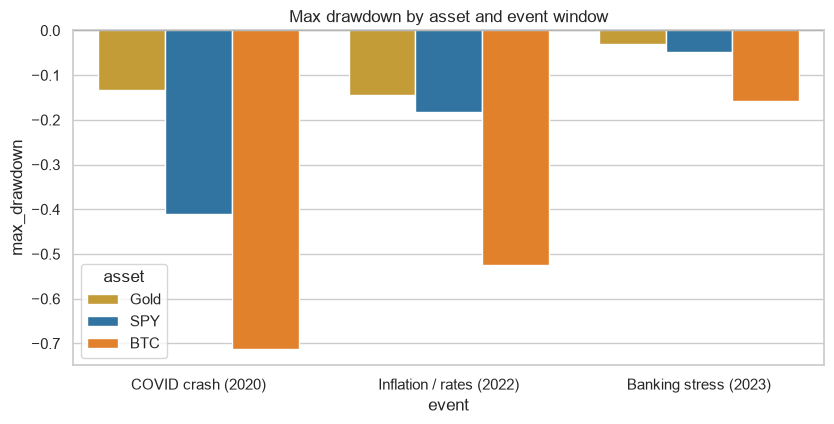

In [5]:
EVENTS = {
    "COVID crash (2020)": ("2020-02-15", "2020-04-30"),
    "Inflation / rates (2022)": ("2022-06-01", "2022-10-31"),
    "Banking stress (2023)": ("2023-03-01", "2023-04-30"),
}

def max_drawdown(log_returns):
    cum = pd.Series(log_returns).dropna().cumsum()
    return float((cum - cum.cummax()).min())

dd_rows = []
for name, (start, end) in EVENTS.items():
    sub = df.loc[(df["Date"] >= start) & (df["Date"] <= end), RET_COLS].dropna()
    dd_rows.append({
        "event": name,
        "Gold_max_drawdown": max_drawdown(sub["gold_ret"]),
        "SPY_max_drawdown": max_drawdown(sub["spy_ret"]),
        "BTC_max_drawdown": max_drawdown(sub["btc_ret"]),
    })
dd_df = pd.DataFrame(dd_rows).round(4)
print("Max drawdown inside each event window:")
display(dd_df)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
melt = dd_df.melt(id_vars="event",
                  value_vars=["Gold_max_drawdown", "SPY_max_drawdown", "BTC_max_drawdown"],
                  var_name="asset", value_name="max_drawdown")
melt["asset"] = melt["asset"].str.replace("_max_drawdown", "")
sns.barplot(data=melt, x="event", y="max_drawdown", hue="asset",
            palette={"Gold": "goldenrod", "SPY": "tab:blue", "BTC": "tab:orange"}, ax=ax)
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Max drawdown by asset and event window")
plt.tight_layout()
plt.savefig(FIG_DIR / "m4_drawdowns.png", dpi=140, bbox_inches="tight")
plt.show()


## SHAP for Model E, themed by economic group


Themed SHAP attribution on the Model E test window:


,n_features,sum_mean_abs_shap,share_of_total_pct
theme,,,
Cross-asset momentum,9,1.5301,42.259998
Macro-stress block,14,0.7033,19.420000
Technicals (RSI),8,0.6191,17.100000
Volatility levels,12,0.4498,12.420000
Other macro,12,0.3184,8.790000


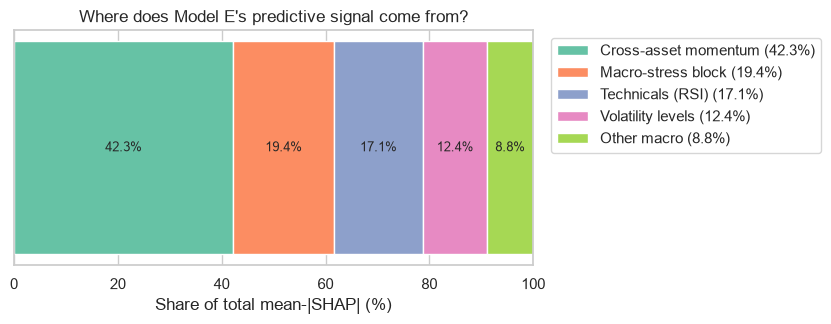

In [6]:
xgb_E = XGBClassifier(
    n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
    colsample_bytree=0.9, eval_metric="logloss", random_state=42, n_jobs=-1, verbosity=0,
).fit(X_tr_E, y_tr_E)
booster = xgb_E.get_booster()
contribs_te = booster.predict(xgb.DMatrix(X_te_E, feature_names=FEATURE_COLS), pred_contribs=True)
shap_te = contribs_te[:, :-1]
mean_abs_shap = pd.Series(np.abs(shap_te).mean(axis=0), index=FEATURE_COLS)

def classify_feature(f):
    if f.startswith(("gold_ret_lag", "spy_ret_lag", "btc_ret_lag")):
        return "Cross-asset momentum"
    if f.startswith(("stress_", "High_Yield_Spread", "Financial_Stress_Index", "Volatility_Index")):
        return "Macro-stress block"
    if "Rolling_Vol_30d" in f:
        return "Volatility levels"
    if f.startswith(("SPY_RSI_14", "GLD_RSI_14")):
        return "Technicals (RSI)"
    return "Other macro"

theme_of = {f: classify_feature(f) for f in FEATURE_COLS}
theme_contrib = pd.DataFrame({
    "feature": FEATURE_COLS,
    "theme": [theme_of[f] for f in FEATURE_COLS],
    "mean_abs_shap": mean_abs_shap.values,
})
theme_summary = theme_contrib.groupby("theme")["mean_abs_shap"].sum().sort_values(ascending=False)
theme_share = (theme_summary / theme_summary.sum() * 100).round(2)
theme_table = pd.DataFrame({
    "n_features": theme_contrib.groupby("theme").size(),
    "sum_mean_abs_shap": theme_summary.round(4),
    "share_of_total_pct": theme_share,
}).sort_values("share_of_total_pct", ascending=False)
print("Themed SHAP attribution on the Model E test window:")
display(theme_table)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
order = theme_table.index.tolist()
left = 0.0
colors = sns.color_palette("Set2", n_colors=len(order))
for color, name in zip(colors, order):
    val = float(theme_share[name])
    ax.barh(["Model E"], val, left=left, color=color, label=f"{name} ({val:.1f}%)")
    if val > 4:
        ax.text(left + val / 2, 0, f"{val:.1f}%", va="center", ha="center", fontsize=9)
    left += val
ax.set_xlim(0, 100); ax.set_yticks([])
ax.set_xlabel("Share of total mean-|SHAP| (%)")
ax.set_title("Where does Model E's predictive signal come from?")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "m4_themed_shap.png", dpi=140, bbox_inches="tight")
plt.show()


## SHAP for Logistic vs XGBoost


Spearman rank correlation of mean-|SHAP| (XGBoost vs Logistic): rho = -0.232
Overlap of top-15: 1/15


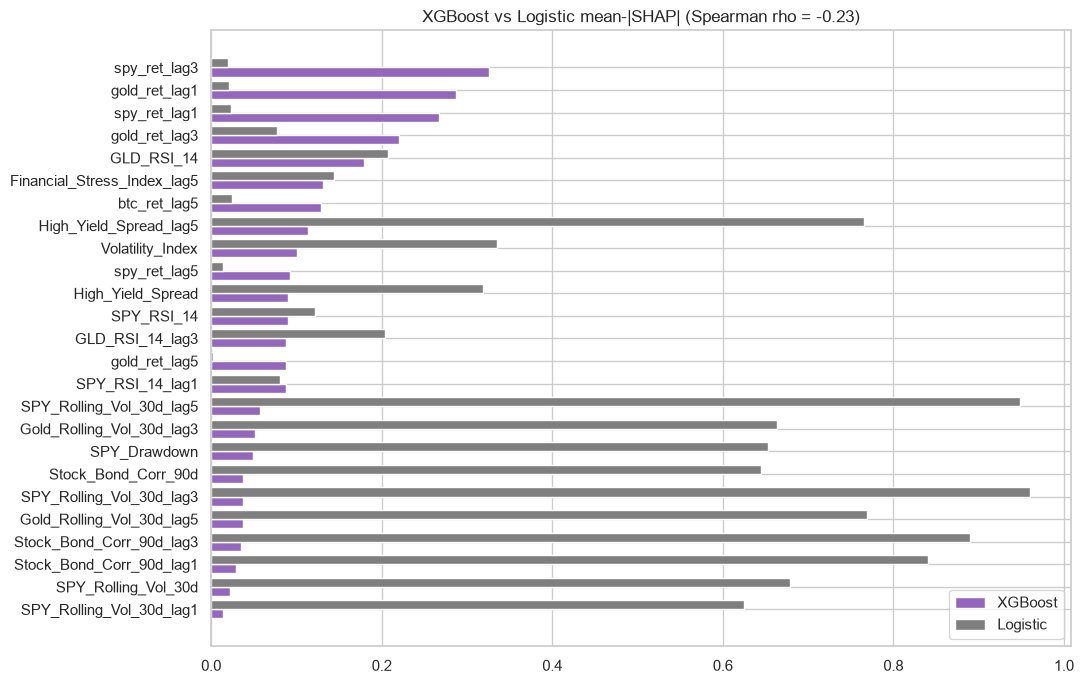

In [7]:
scaler = StandardScaler().fit(X_tr_E)
X_te_E_std = scaler.transform(X_te_E)
logit_E = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
logit_E.fit(scaler.transform(X_tr_E), y_tr_E)
mean_abs_shap_logit = pd.Series(np.abs(X_te_E_std * logit_E.coef_.ravel()).mean(axis=0), index=FEATURE_COLS)
importance_compare = pd.DataFrame({
    "mean_abs_shap_xgb": mean_abs_shap.values,
    "mean_abs_shap_logit": mean_abs_shap_logit.values,
}, index=FEATURE_COLS)
importance_compare["rank_xgb"] = importance_compare["mean_abs_shap_xgb"].rank(ascending=False).astype(int)
importance_compare["rank_logit"] = importance_compare["mean_abs_shap_logit"].rank(ascending=False).astype(int)
importance_compare["rank_diff"] = importance_compare["rank_xgb"] - importance_compare["rank_logit"]
rho_top = stats.spearmanr(importance_compare["mean_abs_shap_xgb"], importance_compare["mean_abs_shap_logit"]).statistic
print(f"Spearman rank correlation of mean-|SHAP| (XGBoost vs Logistic): rho = {rho_top:+.3f}")
top_xgb = importance_compare["mean_abs_shap_xgb"].sort_values(ascending=False).head(15).index
top_logit = importance_compare["mean_abs_shap_logit"].sort_values(ascending=False).head(15).index
print(f"Overlap of top-15: {len(set(top_xgb) & set(top_logit))}/15")
union = list(top_xgb.tolist() + [f for f in top_logit if f not in top_xgb])[:25]
plot_df = importance_compare.loc[union, ["mean_abs_shap_xgb", "mean_abs_shap_logit"]].sort_values("mean_abs_shap_xgb")
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(plot_df))
ax.barh(y - 0.20, plot_df["mean_abs_shap_xgb"], height=0.4, color="tab:purple", label="XGBoost")
ax.barh(y + 0.20, plot_df["mean_abs_shap_logit"], height=0.4, color="tab:gray", label="Logistic")
ax.set_yticks(y); ax.set_yticklabels(plot_df.index)
ax.set_title(f"XGBoost vs Logistic mean-|SHAP| (Spearman rho = {rho_top:+.2f})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "m4_shap_xgb_vs_logit.png", dpi=140, bbox_inches="tight")
plt.show()


## SHAP segmented by stress regime


Test-window calm days: 623, stress days: 199


,calm_share_pct,stress_share_pct,delta_stress_minus_calm_pct
theme,,,
Cross-asset momentum,41.660000,44.160000,2.50
Macro-stress block,20.490000,16.030001,-4.46
Technicals (RSI),16.969999,17.510000,0.55
Volatility levels,11.630000,14.940000,3.31
Other macro,9.250000,7.360000,-1.88


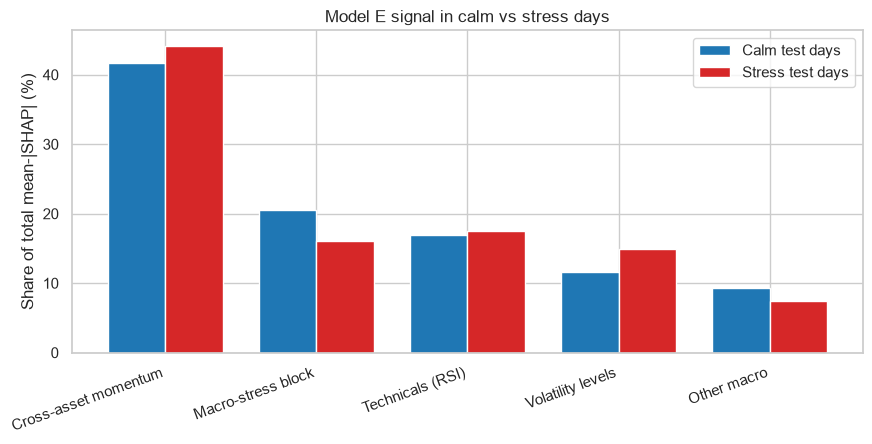

In [8]:
stress_idx = FEATURE_COLS.index("stress_any_t")
te_stress_mask = X_te_E[:, stress_idx] == 1
te_calm_mask = X_te_E[:, stress_idx] == 0
print(f"Test-window calm days: {te_calm_mask.sum()}, stress days: {te_stress_mask.sum()}")

def themed_shares(mat):
    abs_means = pd.Series(np.abs(mat).mean(axis=0), index=FEATURE_COLS)
    by_theme = pd.DataFrame({"theme": [theme_of[f] for f in FEATURE_COLS], "mean_abs_shap": abs_means.values})
    s = by_theme.groupby("theme")["mean_abs_shap"].sum()
    return s / s.sum() * 100

seg_table = pd.DataFrame({
    "calm_share_pct": themed_shares(shap_te[te_calm_mask]),
    "stress_share_pct": themed_shares(shap_te[te_stress_mask]),
})
seg_table["delta_stress_minus_calm_pct"] = (seg_table["stress_share_pct"] - seg_table["calm_share_pct"]).round(2)
seg_table = seg_table.round(2).sort_values("calm_share_pct", ascending=False)
display(seg_table)
x = np.arange(len(seg_table))
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(x - 0.19, seg_table["calm_share_pct"], 0.38, color="tab:blue", label="Calm test days")
ax.bar(x + 0.19, seg_table["stress_share_pct"], 0.38, color="tab:red", label="Stress test days")
ax.set_xticks(x)
ax.set_xticklabels(seg_table.index, rotation=20, ha="right")
ax.set_ylabel("Share of total mean-|SHAP| (%)")
ax.set_title("Model E signal in calm vs stress days")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "m4_shap_calm_vs_stress.png", dpi=140, bbox_inches="tight")
plt.show()


## Why did the MLP fail?


In [9]:
def mlp_metrics(name, mdl, X_tr, y_tr, X_te, y_te):
    pr_tr = mdl.predict_proba(X_tr)[:, 1]
    pr_te = mdl.predict_proba(X_te)[:, 1]
    p_tr = (pr_tr >= 0.5).astype(int)
    p_te = (pr_te >= 0.5).astype(int)
    return {
        "model": name,
        "train_acc": accuracy_score(y_tr, p_tr),
        "test_acc": accuracy_score(y_te, p_te),
        "train_minus_test_acc": accuracy_score(y_tr, p_tr) - accuracy_score(y_te, p_te),
        "test_bal_acc": balanced_accuracy_score(y_te, p_te),
        "test_roc_auc": roc_auc_score(y_te, pr_te),
        "test_brier": brier_score_loss(y_te, pr_te),
        "test_log_loss": log_loss(y_te, np.clip(pr_te, 1e-6, 1 - 1e-6)),
        "test_f1": f1_score(y_te, p_te, zero_division=0),
    }

mlp_m2 = Pipeline([
    ("sc", StandardScaler()),
    ("clf", MLPClassifier(hidden_layer_sizes=(64, 64), activation="relu", solver="adam",
                          alpha=1e-3, max_iter=400, random_state=42)),
]).fit(X_tr_E, y_tr_E)
mlp_fix = Pipeline([
    ("sc", StandardScaler()),
    ("clf", MLPClassifier(hidden_layer_sizes=(64, 64), activation="relu", solver="adam",
                          alpha=1e-2, max_iter=400, random_state=42,
                          early_stopping=True, validation_fraction=0.15)),
]).fit(X_tr_E, y_tr_E)
display(pd.DataFrame([
    mlp_metrics("MLP (2x64, alpha=1e-3)", mlp_m2, X_tr_E, y_tr_E, X_te_E, y_te_E),
    mlp_metrics("MLP + early stop, alpha=1e-2", mlp_fix, X_tr_E, y_tr_E, X_te_E, y_te_E),
]).round(4))

top10 = mean_abs_shap.sort_values(ascending=False).head(10).index.tolist()
ks_rows = []
for f in top10:
    j = FEATURE_COLS.index(f)
    stat, p = stats.ks_2samp(X_tr_E[:, j], X_te_E[:, j])
    ks_rows.append({"feature": f, "KS": float(stat), "p": float(p), "shift_p_lt_0.01": p < 0.01})
ks_df = pd.DataFrame(ks_rows)
print("KS train vs test on top-10 mean-|SHAP| features:")
display(ks_df.round(4))
print("features with KS p < 0.01:", int(ks_df["shift_p_lt_0.01"].sum()), "/", len(ks_df))


,model,train_acc,test_acc,train_minus_test_acc,test_bal_acc,test_roc_auc,test_brier,test_log_loss,test_f1
0,"MLP (2x64, alpha=1e-3)",1.0000,0.5292,0.4708,0.545,0.5673,0.4377,3.6077,0.4994
1,"MLP + early stop, alpha=1e-2",0.6683,0.6144,0.0539,0.498,0.5098,0.2392,0.6723,0.0000


KS train vs test on top-10 mean-|SHAP| features:


,feature,KS,p,shift_p_lt_0.01
0,spy_ret_lag3,0.0383,0.2823,False
1,gold_ret_lag1,0.0966,0.0000,True
2,spy_ret_lag1,0.0367,0.3278,False
3,gold_ret_lag3,0.0966,0.0000,True
4,GLD_RSI_14,0.2353,0.0000,True
5,Financial_Stress_Index_lag5,0.4677,0.0000,True
6,btc_ret_lag5,0.0556,0.0327,False
7,High_Yield_Spread_lag5,0.7267,0.0000,True
8,Volatility_Index,0.1687,0.0000,True
9,spy_ret_lag5,0.0367,0.3278,False


features with KS p < 0.01: 6 / 10


## Takeaway

VIX intensity is the only driver whose deciles line up with a larger Gold–SPY spread. Gold’s beta to SPY falls in stress; Bitcoin’s rises. Model E is mostly lagged cross-asset returns, not a pure macro-stress classifier. The MLP’s train/test collapse is covariate shift, not just a missing early-stopping flag.
